### %pylab inline
import os
import gc
import fitsio
import catutil
import treecorr
import numpy as np
import astropy.io.ascii as ascii

I copy the data from [here](https://github.com/PrincetonUniversity/HSC-WeakLens/blob/master/requirements/estar_estar.dat)
to my working directory and read the data

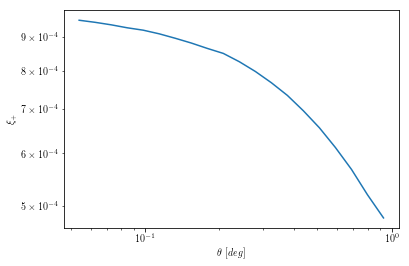

In [56]:
wDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/cosmicShear/systematics/'
eeS16=ascii.read(os.path.join(wDir,'estar_estar_s16a.dat'))
# plot the column xip_all vs theta
plt.close()
plt.plot(eeS16['theta'],eeS16['xip_all'])
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\theta~[deg]$')
plt.ylabel(r'$\xi_+$')
plt.show()

This correlation data was used to determine the requirement on fractional additive bias ($|\delta~a|$), see the 
[code in repository](https://github.com/PrincetonUniversity/HSC-WeakLens/blob/9a3c09a3d60a4f15ebeb1fbfb30309b89e38d8fa/requirements/requirements.py#L114)


Since I got a much stringent requirement on $\delta~a$ in S19A following the code in the repository, I recalculated the $<e_{star}e_{star}>$ using the S16A data

In [ ]:
# join the all-field combined star catalog (only column ra,dec,epsf)
oDir='wrkDir/database/s16/S16AStandardV2/field/'
raA=[];decA=[];ep1A=[];ep2A=[]
for fieldname in catutil.field_names:
    __dat=fitsio.read(os.path.join(oDir,'%s_stars.fits' %fieldname))
    print(len(__dat))
    ra,dec=catutil.get_radec(__dat)
    epsf1,epsf2=catutil.get_psf_ellip(__dat)
    raA.append(ra);decA.append(dec)
    ep1A.append(epsf1);ep2A.append(epsf2)
    del __dat,ra,dec,epsf1,epsf2
    gc.collect()
raA=np.hstack(raA);decA=np.hstack(decA)
ep1A=np.hstack(ep1A);ep2A=np.hstack(ep2A)
# <ee> estimate
catE1   =   treecorr.Catalog(g1=ep1A,g2=-ep2A,\
    ra=raA,dec=decA,ra_units='deg',dec_units='deg')
corE1   =   treecorr.GGCorrelation(nbins=30,min_sep=0.05,max_sep=1.,sep_units='deg')
corE1.process(catE1)


+ The following figure compare the signal $<e_{star}e_{star}>$ (labeled as new), estimated from S16A star catalog, with the $\xi_+$ column in the data (labeled as old) 
+ There is a factor of 4 difference
+ The result indicate that the file [here](https://github.com/PrincetonUniversity/HSC-WeakLens/blob/master/requirements/estar_estar.dat) is actually $<g_{star}g_{star}>$ although the file name is estar_estar.dat, which is confusing

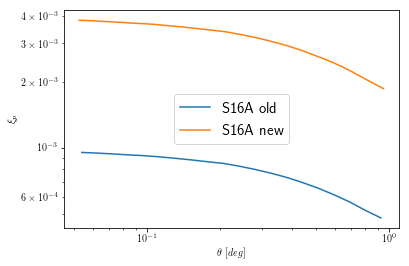

In [55]:
plt.close()
plt.plot(eeS16['theta'],eeS16['xip_all'],label='S16A old')
plt.plot(corE1.rnom,corE1.xip,label='S16A new')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\theta~[deg]$')
plt.ylabel(r'$\xi_+$')
plt.legend(loc='center',fontsize=15)
plt.show()